In [1]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Statevector, Kraus, Choi, DensityMatrix, concurrence
from qiskit.visualization import array_to_latex
import numpy as np
import matplotlib.pyplot as plt


Looking for a unitary operator $U_1$ such that:
$$ U_1\ket{00}=\frac{1}{\sqrt{2}}(\ket{01}+\ket{10})$$
Looking at the bell state and working backwards: \
We need to apply a hadamard gate to the fist qubit (q0) which will construct a superposition of $\ket0$ and $\ket1$ and leave the 2nd qubit (q1) as 0:
$$(H \otimes I)\ket{00} = \left( \frac{\ket0+\ket1}{\sqrt{2}}\right) \otimes \ket0$$
$$= \frac{1}{\sqrt{2}}(\ket{00}+\ket{10}) $$

Now looking at back our bell state, we already have $\ket{10}$ sorted. We just need a way to flip $\ket{00}$ to $\ket{01}$. I'm thinking we need a CNOT gate with q0 as the control, but this wont change anything because q0 is 0. If q1 was 1 instead of 0 at the start, we will end up with a $\ket{01}$, which will stay the same after applying a CNOT, and a $\ket{11}$, which will change q1 to 0 after the CNOT.So applying a X gate to q1 then a CNOT with q0 as the control will give us the state we need. So we start again and apply an X gate to q1:
$$(I \otimes X)\ket{00} = \ket{01} $$
Then apply Hadamard gate to q0:
$$(H \otimes I)\ket{01} = \left( \frac{\ket0+\ket1}{\sqrt{2}}\right) \otimes \ket1$$
$$= \frac{1}{\sqrt{2}}(\ket{01}+\ket{11}) $$
Then apply CNOT with q0 as the control:
$$ CNOT \frac{1}{\sqrt{2}}(\ket{01}+\ket{11}) = \frac{1}{\sqrt{2}}(\ket{01}+\ket{10})$$
And we now have our desired state. In code:

In [2]:
# create a 2 qubit circuit (starts at ket00)
qc = QuantumCircuit(2)

#apply x to q1 for bit flip (result: ket01):
qc.x(1)  
#apply hadamard to q0 (result: (ket01 + ket11)/sqrt(2))
qc.h(0)
#apply cnot (q0 control, q1 target) (result: (ket01 + ket10)/sqrt(2))
qc.cx(0, 1)

#pick out our unitary operator from the circuit:
U1 = Operator(qc)
print(U1.data)



[[ 0.        +0.j  0.        +0.j  0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j  0.        +0.j  0.        +0.j]
 [ 0.70710678+0.j  0.70710678+0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  0.        +0.j  0.70710678+0.j -0.70710678+0.j]]


In [3]:
#check U1 is unitary
U1.data.conj().T @ U1.data

array([[ 1.00000000e+00+0.j,  2.23711432e-17+0.j,  0.00000000e+00+0.j,
         0.00000000e+00+0.j],
       [ 2.23711432e-17+0.j,  1.00000000e+00+0.j,  0.00000000e+00+0.j,
         0.00000000e+00+0.j],
       [ 0.00000000e+00+0.j,  0.00000000e+00+0.j,  1.00000000e+00+0.j,
        -2.23711432e-17+0.j],
       [ 0.00000000e+00+0.j,  0.00000000e+00+0.j, -2.23711432e-17+0.j,
         1.00000000e+00+0.j]])

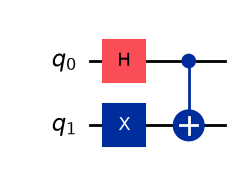

In [4]:
#draw the circuit
qc.draw(output = 'mpl')

Now we take a similar approach to find $U_2$ such that
$$ U_2\ket{00}=\frac{1}{\sqrt{2}}(\ket{00}+\ket{11})$$
Its clear that we need a hadamard on q0, then a CNOT with q0 as the control.


In [5]:
qc2 = QuantumCircuit(2)

#apply hadamard to q0 (result: (ket00 + ket10)/sqrt(2))
qc2.h(0)
#apply cnot (q0 control, q1 target) (result: (ket00 + ket11)/sqrt(2))
qc2.cx(0,1)
U2 = Operator(qc2)
print(U2.data)


[[ 0.70710678+0.j  0.70710678+0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  0.        +0.j  0.70710678+0.j -0.70710678+0.j]
 [ 0.        +0.j  0.        +0.j  0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j  0.        +0.j  0.        +0.j]]


In [6]:
#check U2 is unitary
U2.data.conj().T @ U2.data

array([[ 1.00000000e+00+0.j, -2.23711432e-17+0.j,  0.00000000e+00+0.j,
         0.00000000e+00+0.j],
       [-2.23711432e-17+0.j,  1.00000000e+00+0.j,  0.00000000e+00+0.j,
         0.00000000e+00+0.j],
       [ 0.00000000e+00+0.j,  0.00000000e+00+0.j,  1.00000000e+00+0.j,
         2.23711432e-17+0.j],
       [ 0.00000000e+00+0.j,  0.00000000e+00+0.j,  2.23711432e-17+0.j,
         1.00000000e+00+0.j]])

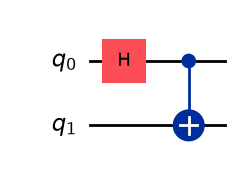

In [7]:
#draw the circuit
qc2.draw("mpl")

In [8]:
#Test U1:


psi_in = Statevector.from_label('00')
psi_out = psi_in.evolve(U1)

print(psi_out.draw('latex_source'))


\frac{\sqrt{2}}{2} |01\rangle+\frac{\sqrt{2}}{2} |10\rangle


$$\frac{\sqrt{2}}{2} |01\rangle+\frac{\sqrt{2}}{2} |10\rangle$$
as expected.

In [9]:
#Test U2:
psi_in = Statevector.from_label('00')
psi_out = psi_in.evolve(U2)
print(psi_out.draw('latex_source'))

\frac{\sqrt{2}}{2} |00\rangle+\frac{\sqrt{2}}{2} |11\rangle


$$\frac{\sqrt{2}}{2} |00\rangle+\frac{\sqrt{2}}{2} |11\rangle $$

as expected

In [11]:
#Construct mixed unitary channel from U1 and U2
p0 = 0.7
p1 = 1-p0

kruas_ops = [np.sqrt(p0)*U1.data, np.sqrt(p1)*U2.data]
channel = Kraus(kruas_ops)

#pick an initial state
rho0 = DensityMatrix.from_label('00')

rho_final = rho0.evolve(channel)

#check concurrence of final state
final_entanglement = concurrence(rho_final)
print("Concurrence of final state: ", final_entanglement)

Concurrence of final state:  0.3999999999999998


Text(0, 0.5, 'Concurrence')

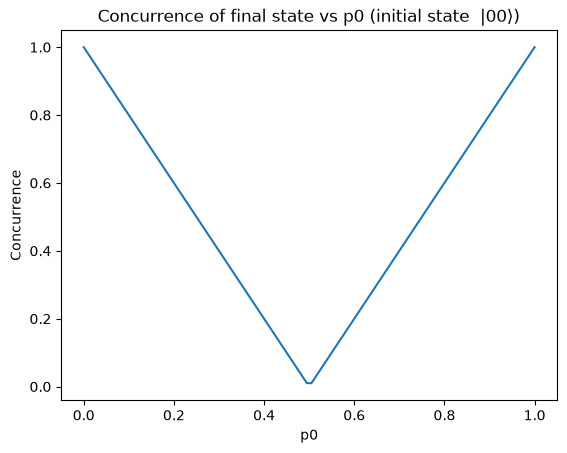

In [12]:
# try for a range of p0 values
p0 = np.linspace(0,1,100)
p1 = 1-p0
concurrences = []

for p in p0:
    kruas_ops = [np.sqrt(p)*U1.data, np.sqrt(1-p)*U2.data]
    channel = Kraus(kruas_ops)
    rho_final = rho0.evolve(channel)
    final_entanglement = concurrence(rho_final)
    concurrences.append(final_entanglement)


plt.plot(p0, concurrences)
plt.title("Concurrence of final state vs p0 (initial state  $|00\\rangle$)")
plt.xlabel("p0")
plt.ylabel("Concurrence")


Text(0, 0.5, 'Concurrence')

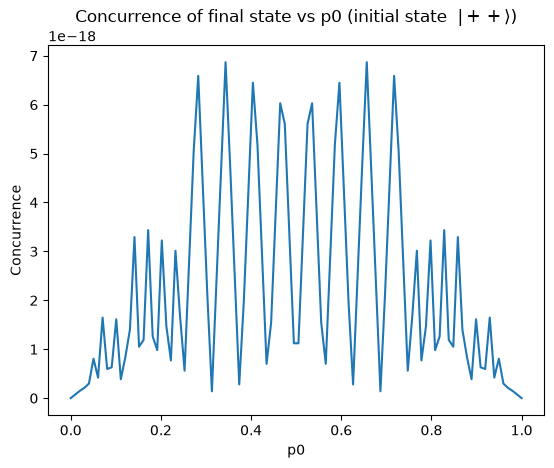

In [ ]:
#try for a different initial state
rho0 = DensityMatrix.from_label('++')
p0 = np.linspace(0,1,100)
p1 = 1-p0
concurrences = []

for p in p0:
    kruas_ops = [np.sqrt(p)*U1.data, np.sqrt(1-p)*U2.data]
    channel = Kraus(kruas_ops)
    rho_final = rho0.evolve(channel)
    final_entanglement = concurrence(rho_final)
    concurrences.append(final_entanglement)


plt.plot(p0, concurrences)
plt.title("Concurrence of final state vs p0 (initial state  $|++\\rangle$)")
plt.xlabel("p0")
plt.ylabel("Concurrence")

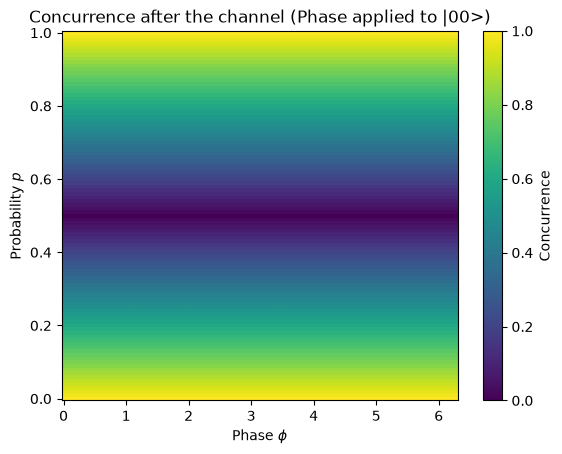

In [22]:
p_values = np.linspace(0, 1, 101)
phis = np.linspace(0, 2 * np.pi, 101)
concurrence_grid = np.zeros((len(p_values), len(phis)))

for i, p in enumerate(p_values):
    # build the mixed unitary channel for this value of p
    kraus_ops = [np.sqrt(p) * U1.data, np.sqrt(1 - p) * U2.data]
    channel = Kraus(kraus_ops)

    for j, phi in enumerate(phis):
        # |Phi_phi> = (|00> + exp(i*phi)|11>) / sqrt(2)
        psi = Statevector(
            np.array([np.exp(1j *phi), 0, 0, 0])
        )
        rho0 = DensityMatrix(psi)
        rho_final = rho0.evolve(channel)
        concurrence_grid[i, j] = concurrence(rho_final)

plt.pcolormesh(
    phis, p_values, concurrence_grid,
    shading="auto", vmin=0, vmax=1
)
plt.xlabel(r"Phase $\phi$")
plt.ylabel(r"Probability $p$")
plt.title("Concurrence after the channel (Phase applied to |00>)")
plt.colorbar(label="Concurrence")
plt.show()

Text(0, 0.5, 'Concurrence')

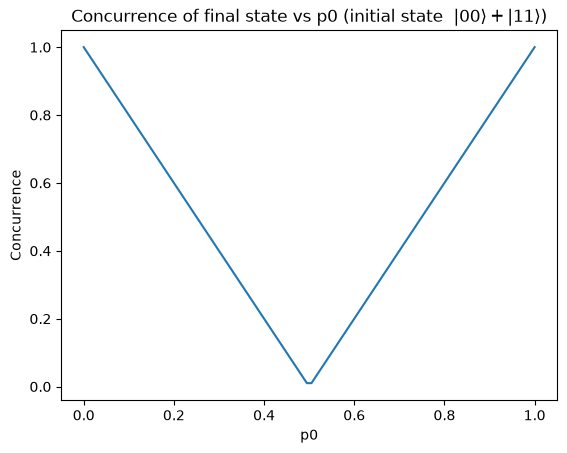

In [33]:
#try for a different initial state
initial = (Statevector.from_label('00')+Statevector.from_label('11')) / np.sqrt(2)
rho0 = DensityMatrix(initial)
p0 = np.linspace(0,1,100)
p1 = 1-p0
concurrences = []

for p in p0:
    kruas_ops = [np.sqrt(p)*U1.data, np.sqrt(1-p)*U2.data]
    channel = Kraus(kruas_ops)
    rho_final = rho0.evolve(channel)
    final_entanglement = concurrence(rho_final)
    concurrences.append(final_entanglement)


plt.plot(p0, concurrences)
plt.title("Concurrence of final state vs p0 (initial state  $|00\\rangle + |11\\rangle$)")
plt.xlabel("p0")
plt.ylabel("Concurrence")

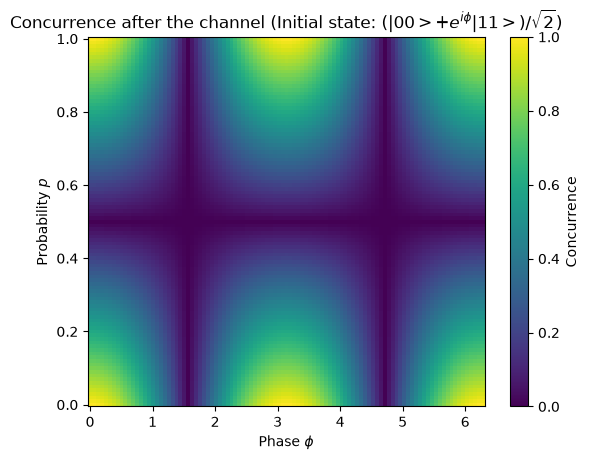

In [28]:
p_values = np.linspace(0, 1, 101)
phis = np.linspace(0, 2 * np.pi, 101)
concurrence_grid = np.zeros((len(p_values), len(phis)))

for i, p in enumerate(p_values):
    # build the mixed unitary channel for this value of p
    kraus_ops = [np.sqrt(p) * U1.data, np.sqrt(1 - p) * U2.data]
    channel = Kraus(kraus_ops)

    for j, phi in enumerate(phis):
        # |Phi_phi> = (|00> + exp(i*phi)|11>) / sqrt(2)
        psi = Statevector(
            np.array([1, 0, 0, np.exp(1j *phi)]) / np.sqrt(2)
        )
        rho0 = DensityMatrix(psi)
        rho_final = rho0.evolve(channel)
        concurrence_grid[i, j] = concurrence(rho_final)

plt.pcolormesh(
    phis, p_values, concurrence_grid,
    shading="auto", vmin=0, vmax=1
)
plt.xlabel(r"Phase $\phi$")
plt.ylabel(r"Probability $p$")
plt.title("Concurrence after the channel (Initial state: ($|00> + e^{i\\phi}|11>)/\\sqrt{2})$")
plt.colorbar(label="Concurrence")
plt.show()